**Segmentasi Citra Berbasis Similaritas: Clustering dan Watershed**

---

### 1. Konsep Segmentasi Berbasis Clustering

Segmentasi berbasis clustering memanfaatkan algoritma pembelajaran tak terawasi (unsupervised learning) untuk mengelompokkan piksel berdasarkan fitur seperti intensitas, warna, atau koordinat spasial.

Algoritma yang umum digunakan:

* **K-Means Clustering**: Mengelompokkan piksel ke dalam *k* klaster berdasarkan jarak ke pusat klaster.
* **Mean Shift**, **DBSCAN**, dan lain-lain.

### 2. Implementasi K-Means Clustering

```python
  import cv2
  import numpy as np
  import matplotlib.pyplot as plt

  img = cv2.imread('image.jpg')
  img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
  plt.imshow(img_rgb)
  plt.title('RGB Original Image')
  plt.axis('off')
  plt.show()

  Z = img_rgb.reshape((-1,3))
  Z = np.float32(Z)

  criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
  K = 3
  ret,label,center=cv2.kmeans(Z,K,None,criteria,10,cv2.KMEANS_RANDOM_CENTERS)

  center = np.uint8(center)
  res = center[label.flatten()]
  segmented_img = res.reshape((img.shape))

  plt.imshow(segmented_img)
  plt.title('K-Means Segmentation')
  plt.axis('off')
  plt.show()
```

### 3. Konsep Segmentasi Watershed

Watershed adalah algoritma berbasis morfologi yang memodelkan citra sebagai topografi. Area terang (intensitas tinggi) dianggap sebagai puncak dan area gelap (intensitas rendah) sebagai lembah. Tujuannya adalah membanjiri lembah dari marker (penanda), lalu membuat batas di titik pertemuan antara banjir.
Watershed efektif jika dikombinasikan dengan marker dan preprocessing.

### 4. Implementasi Watershed di Python

```python
  img = cv2.imread('image.jpg')
  gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
  ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

  # Noise removal
  kernel = np.ones((3,3), np.uint8)
  opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)

  # Sure background
  sure_bg = cv2.dilate(opening, kernel, iterations=3)

  # Sure foreground
  dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
  ret, sure_fg = cv2.threshold(dist_transform, 0.7*dist_transform.max(), 255, 0)

  # Unknown region
  sure_fg = np.uint8(sure_fg)
  unknown = cv2.subtract(sure_bg, sure_fg)

  # Marker labelling
  ret, markers = cv2.connectedComponents(sure_fg)
  markers = markers + 1
  markers[unknown == 255] = 0

  markers = cv2.watershed(img, markers)
  img[markers == -1] = [255, 0, 0]

  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.title('Watershed Result')
  plt.axis('off')
  plt.show()
```

---

### 5. Visualisasi Eksperimen Tambahan

#### Menguji jumlah klaster *K* yang berbeda pada K-Means:
```python
  for k in [2, 4, 6]:
      _, labels, centers = cv2.kmeans(np.float32(img_reshaped), k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)
      segmented_img = centers[labels.flatten()].reshape(img.shape).astype(np.uint8)
      plt.figure()
      plt.imshow(cv2.cvtColor(segmented_img, cv2.COLOR_BGR2RGB))
      plt.title(f'K-Means with k={k}')
      plt.axis('off')
      plt.show()
```

#### Menambahkan Preprocessing dengan CLAHE untuk Watershed:
```python
  clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
  gray_clahe = clahe.apply(gray)
  # Gunakan gray_clahe dalam preprocessing untuk Watershed
```

#### Menggabungkan Watershed dengan Deteksi Tepi dan Thresholding untuk Marker Lebih Akurat:
```python
  edges = cv2.Canny(gray, 100, 200)
  edges_dilated = cv2.dilate(edges, kernel, iterations=1)
  ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
  combined_marker = cv2.bitwise_or(edges_dilated, thresh)
  # Lanjutkan dengan langkah marker dan watershed seperti sebelumnya
  # Gunakan 'combined_marker' sebagai referensi untuk sure_fg
```

#### Mengkombinasikan Clustering dan Watershed untuk Segmentasi Lebih Akurat:
Gabungan clustering (misalnya K-Means) dan watershed dapat meningkatkan akurasi segmentasi.
* Gunakan hasil clustering sebagai dasar penentuan marker.
* Terapkan watershed berdasarkan hasil threshold dari cluster tertentu atau perbedaan antar cluster.

```python
  # Asumsikan segmented_img dari K-Means telah tersedia
  gray_clustered = cv2.cvtColor(segmented_img, cv2.COLOR_RGB2GRAY)
  ret, thresh_clustered = cv2.threshold(gray_clustered, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

  # Preprocessing untuk marker
  opening = cv2.morphologyEx(thresh_clustered, cv2.MORPH_OPEN, kernel, iterations=2)
  sure_bg = cv2.dilate(opening, kernel, iterations=3)
  dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
  ret, sure_fg = cv2.threshold(dist_transform, 0.7 * dist_transform.max(), 255, 0)
  sure_fg = np.uint8(sure_fg)
  unknown = cv2.subtract(sure_bg, sure_fg)

  ret, markers = cv2.connectedComponents(sure_fg)
  markers = markers + 1
  markers[unknown == 255] = 0

  markers = cv2.watershed(img, markers)
  img[markers == -1] = [255, 0, 0]

  plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
  plt.title('Clustering + Watershed')
  plt.axis('off')
  plt.show()
```

---

### 6. Kesimpulan

* Segmentasi berbasis clustering efektif untuk pemisahan objek berdasarkan kesamaan warna/intensitas (tekstur homogen), sementara watershed sangat baik untuk segmentasi objek bersentuhan (objek dengan batas yang jelas).
* Eksperimen parameter penting untuk mendapatkan hasil segmentasi terbaik.
* Preprocessing seperti CLAHE, serta deteksi tepi dan thresholding sangat membantu dalam memperjelas batas objek.
* Kombinasikan Clustering dan Watershed dapat menghasilkan segmentasi yang lebih akurat.

### Implementasi 

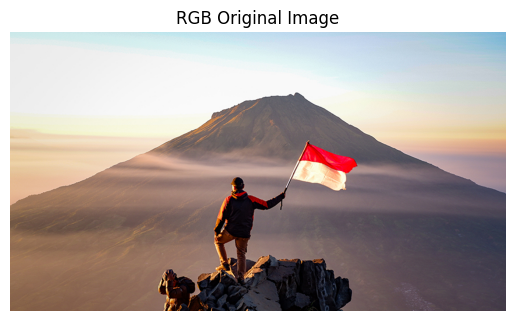

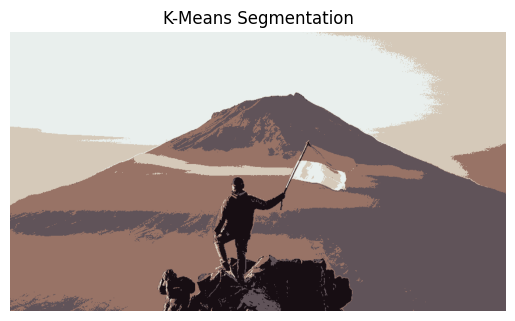

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread('panorama.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.title('RGB Original Image')
plt.axis('off')
plt.show()

Z = img_rgb.reshape((-1,3))
Z = np.float32(Z)

criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 10, 1.0)
K = 5
ret,label,center=cv2.kmeans(Z,K,None,criteria,10,cv2.KMEANS_RANDOM_CENTERS)

center = np.uint8(center)
res = center[label.flatten()]
segmented_img = res.reshape((img.shape))

plt.imshow(segmented_img)
plt.title('K-Means Segmentation')
plt.axis('off')
plt.show()

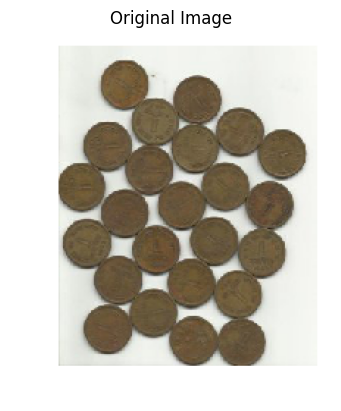

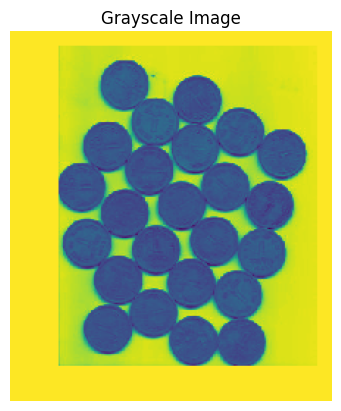

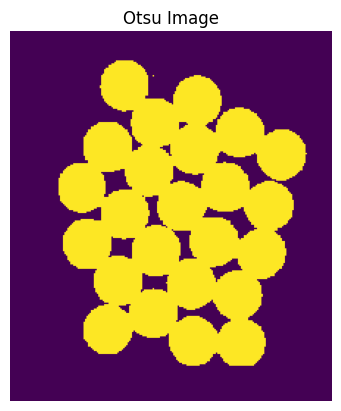

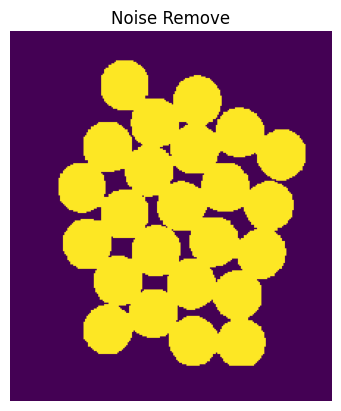

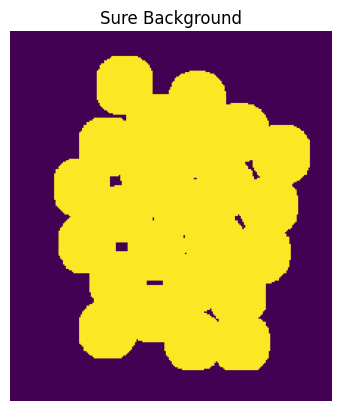

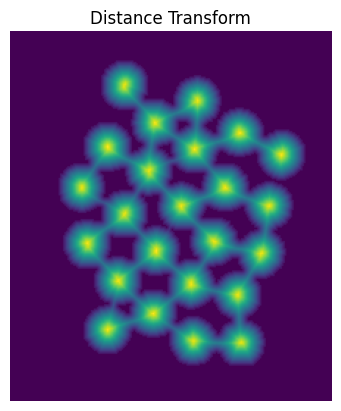

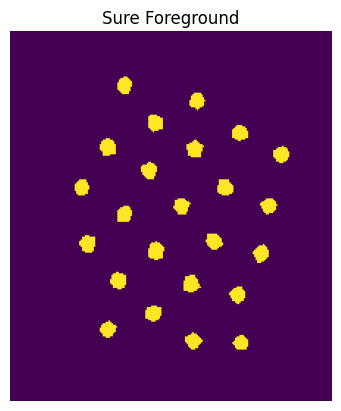

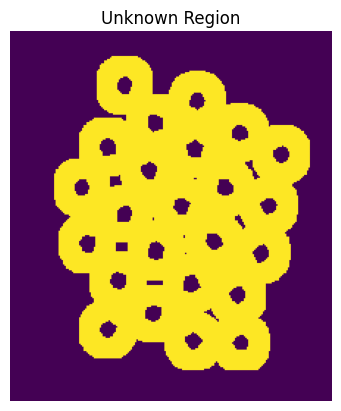

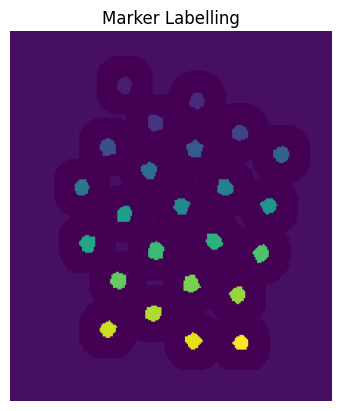

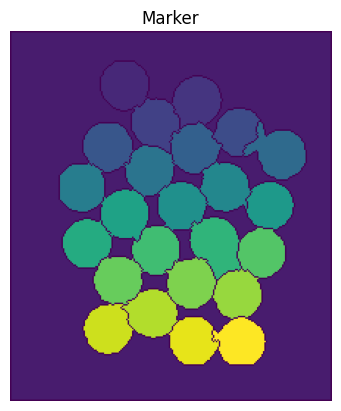

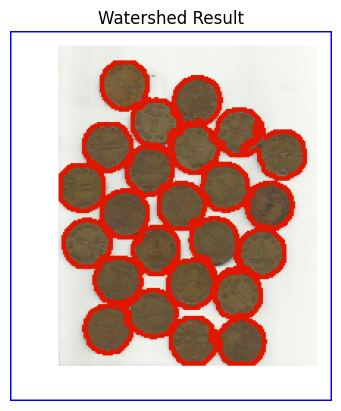

In [2]:
img = cv2.imread('coin.png')
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Original Image')
plt.axis('off')
plt.show()

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
plt.imshow(gray)
plt.title('Grayscale Image')
plt.axis('off')
plt.show()

ret, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
plt.imshow(thresh)
plt.title('Otsu Image')
plt.axis('off')
plt.show()

# Noise removal
kernel = np.ones((3,3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)
plt.imshow(opening)
plt.title('Noise Remove')
plt.axis('off')
plt.show()

# Sure background
sure_bg = cv2.dilate(opening, kernel, iterations=3)
plt.imshow(sure_bg)
plt.title('Sure Background')
plt.axis('off')
plt.show()

# Sure foreground
dist_transform = cv2.distanceTransform(opening, cv2.DIST_L2, 5)
plt.imshow(dist_transform)
plt.title('Distance Transform')
plt.axis('off')
plt.show()

ret, sure_fg = cv2.threshold(dist_transform, 0.7*dist_transform.max(), 255, 0)
plt.imshow(sure_fg)
plt.title('Sure Foreground')
plt.axis('off')
plt.show()

# Unknown region
sure_fg = np.uint8(sure_fg)
unknown = cv2.subtract(sure_bg, sure_fg)
plt.imshow(unknown)
plt.title('Unknown Region')
plt.axis('off')
plt.show()


# Marker labelling
ret, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0
plt.imshow(markers)
plt.title('Marker Labelling')
plt.axis('off')
plt.show()

markers = cv2.watershed(img, markers)
img[markers == -1] = [255, 0, 0]
plt.imshow(markers)
plt.title('Marker')
plt.axis('off')
plt.show()

labels = np.unique(markers)
coins = []
for label in labels[2:]:
    # Create a binary image in which only the area of the label is in the foreground
    #and the rest of the image is in the background
    target = np.where(markers == label, 255, 0).astype(np.uint8)
    # Perform contour extraction on the created binary image
    contours, hierarchy = cv2.findContours(
        target, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )
    coins.append(contours[0])

img = cv2.drawContours(img, coins, -1, color=(0, 23, 223), thickness=2)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title('Watershed Result')
plt.axis('off')
plt.show()